# 27 - Goals markets: Over/Under 2.5 and Asian handicap (P8-06)

P8-02..05 found no edge in 1X2: the model's log loss is 0.021 worse than the
de-margined market and a blend puts no weight on it. This notebook asks whether
the model does better in markets priced on **goals**, which our xG features
describe directly: **Over/Under 2.5** and the **Asian handicap** (AH) on the
line in `AHh`.

The production model only gives H/D/A, so these markets need a score
distribution. Three goals models, all walk-forward (each season predicted from
earlier seasons only):

- **(a) derived:** Poisson rates (λh, λa) backed out of the model's H/D/A
  (`pH`, `pA` matched exactly, the P6-02 method).
- **(b) Dixon-Coles:** penaltyblog's Dixon-Coles (`src/dixon_coles.py`), refitted
  per league every betting week on that league's previous 3 years (time decay
  ξ = 0.0018), with the low-score correction ρ.
- **(c) Poisson regression:** two Poisson GLMs (home goals, away goals) on team
  attack/defence form (exponentially weighted xG and goals for/against), the
  league's goal rate, EloDiff, league indicators and a new-to-the-league flag.
  Trained on every earlier season.

**Scoring.** O/U: binary log loss of P(over 2.5). AH: the line is the home
side's handicap; quarter lines are half the stake on each neighbouring line.
Each half stake that isn't pushed is a binary cover / not-cover outcome, scored
with P(home covers | not pushed), weighted 1/2 on a quarter line. That
probability is what a de-margined two-way AH price estimates, and the rule is
proper (see `src/betting/goals.py`). Market = proportional de-margined Pinnacle
opening, falling back to the market average (as P8-01).
Paired bootstrap over matches (5,000, seed 42); negative = model better.

**Betting.** P8-03/P8-04 rules on each market: confidence thresholds, value bets
(edge = expected return - 1, with pushes and half results), blended
probabilities, an odds band, plus staking (flat, edge-proportional, ¼ and ½
Kelly) for the chosen rule. Settlement is the P8-01 simulator's (`leg_return`:
pushes and quarter lines already handled). Tune on **22-23/23-24**, report on
**24-25/25-26**, show 26-27 to date. ROI CI from resampling betting weeks.
Every variant goes to `data/processed/betting_variants.csv` (ticket P8-06).

**Fixed before any results were computed:**
1. *Goals model per market:* the lowest tuning-season log loss for that market.
   Betting rules use it.
2. *Betting rule per market:* among that market's variants, at `avg` odds in the
   tuning seasons with at least 150 tuning bets, the highest ROI (ties: more
   bets). Its report-season result is recorded whatever it is.

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import expit, logit
from sklearn.linear_model import PoissonRegressor

from backtest import prepare_matches
from betting.goals import (
    ah_coefficients, ah_log_loss, ah_outcomes, clean_two_way, margin_pmf, p_over,
    poisson_grid, rates_from_hda, two_way_probability, valid_line,
)
from betting.market import prices
from betting.simulate import bootstrap_roi, load_oos, simulate, single, summarise
from betting.staking import bankroll_path, bankroll_stats, edge_plan, flat_plan, kelly_plan
from betting.variants import log_variants
from dixon_coles import _fit_model
from evaluate import paired_bootstrap

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 200)

TEST = ["22-23", "23-24", "24-25", "25-26"]
TUNE, REPORT = TEST[:2], TEST[2:]
CURRENT = "26-27"
PERIODS = {"tune": TUNE, "report": REPORT, "26-27": [CURRENT]}
SOURCES = ["avg", "b365", "max"]  # b365 added for P8-07
MIN_TUNE_BETS = 150
MODELS = ["derived", "dixon-coles", "poisson reg"]
MARKETS = {"OU25": ["O", "U"], "AH": ["H", "A"]}

# Chart colours: categorical slots 1-4 (tuning / report use slots 1-2)
COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
TUNE_COLOUR, REPORT_COLOUR = COLOURS[:2]

def style(ax):
    ax.grid(axis="y", color="#dddddd", linewidth=0.6)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

## Data

`oos_predictions.csv` (P8-01) gives the results, the model's H/D/A and every odds
column. Bad two-way prices are set to missing first: a booksum (1/o₁ + 1/o₂)
under 1 is impossible for one bookmaker or the average, so it's a data error
(e.g. ~50 rows in 25-26 where `AvgAHA` holds the 1X2 away price). The best price
may dip slightly under 1 (floor 0.97). AH lines off the quarter-goal grid (one
`AHh` of 1.83) are dropped.

In [2]:
raw = load_oos()
raw = raw[raw["FTR"].notna()]
oos, removed = clean_two_way(raw)
print("Price pairs set to missing:", {k: v for k, v in removed.items() if v})

oos = oos.sort_values(["MatchDateTime", "Div", "HomeTeam"], kind="stable").reset_index(drop=True)
oos["Week"] = oos["Season"] + "|" + oos["BetWeek"]
N = len(oos)

GOALS_H, GOALS_A = oos["FTHG"].to_numpy(float), oos["FTAG"].to_numpy(float)
MARGIN = GOALS_H - GOALS_A
OVER = (GOALS_H + GOALS_A) > 2.5
LINE = oos["AHh"].to_numpy(float)
LINE_OK = valid_line(LINE)
LINE0 = np.where(LINE_OK, LINE, 0.0)

PERIOD_MASK = {name: oos["Season"].isin(seasons).to_numpy() for name, seasons in PERIODS.items()}
PERIOD_MASK["test"] = oos["Season"].isin(TEST).to_numpy()
PERIOD_WEEKS = {name: pd.unique(oos.loc[mask, "Week"]) for name, mask in PERIOD_MASK.items()}

print(f"{N:,} matches:", oos.groupby("Season").size().to_dict())
print(f"Over 2.5 rate {OVER.mean():.3f}; AH lines usable {LINE_OK.mean():.4f}; "
      f"quarter lines {np.isclose(np.mod(LINE0 * 4, 2), 1).mean():.1%}")

Price pairs set to missing: {'Avg>2.5/Avg<2.5': 1, 'P>2.5/P<2.5': 2, 'Max>2.5/Max<2.5': 22, 'PC>2.5/PC<2.5': 3, 'MaxC>2.5/MaxC<2.5': 222, 'AvgAHH/AvgAHA': 55, 'MaxAHH/MaxAHA': 64, 'PCAHH/PCAHA': 1, 'MaxCAHH/MaxCAHA': 276}
10,171 matches: {'22-23': 2438, '23-24': 2364, '24-25': 2364, '25-26': 2364, '26-27': 641}
Over 2.5 rate 0.544; AH lines usable 0.9993; quarter lines 52.4%


## Goals models

### Features for (c)

Per league, in kick-off order, each team keeps an exponentially weighted average
(decay 0.9 a match, about a 7-match half-life, carried across seasons) of its
xG for/against and goals for/against. Before a match the estimate is shrunk
towards the league's goal rate from the previous season with weight 3 matches,
so a team new to the league starts at the league average and the `new` flag
lets the regression shift it. Only matches before the kick-off are used.

In [3]:
t0 = time.time()
matches, seasons, _ = prepare_matches()
lg = matches[matches["Div"].isin(oos["Div"].unique())].copy()
lg["MatchDateTime"] = pd.to_datetime(lg["MatchDateTime"])
lg["MatchKey"] = lg["Season"] + "|" + lg["Div"] + "|" + lg["HomeTeam"] + "|" + lg["AwayTeam"]
lg = lg.sort_values(["MatchDateTime", "Div", "HomeTeam"], kind="stable").reset_index(drop=True)

DECAY, SHRINK = 0.9, 3.0
STATS = ["xf", "xa", "gf", "ga"]

def team_form(lg):
    out = {f"{side}{s}": np.full(len(lg), np.nan) for side in "ha" for s in STATS + ["new"]}
    out["lgavg"] = np.full(len(lg), np.nan)
    for div, g in lg.groupby("Div", sort=False):
        played = g[g["FTHG"].notna()]
        season_rate = played.groupby("Season").apply(lambda d: (d["FTHG"].sum() + d["FTAG"].sum()) / (2 * len(d)))
        state = {}
        for i, r in g.iterrows():
            earlier = season_rate[season_rate.index < r["Season"]]
            prior = earlier.iloc[-1] if len(earlier) else 1.35
            out["lgavg"][i] = prior
            for side, team in [("h", r["HomeTeam"]), ("a", r["AwayTeam"])]:
                st = state.get(team)
                out[f"{side}new"][i] = float(st is None)
                if st is None:
                    st = state[team] = dict(w=0.0, xf=0.0, xa=0.0, gf=0.0, ga=0.0)
                for s in STATS:
                    out[f"{side}{s}"][i] = (SHRINK * prior + st[s]) / (SHRINK + st["w"])
            if pd.notna(r["FTHG"]):
                hx = r["HomeXG"] if pd.notna(r["HomeXG"]) else r["FTHG"]
                ax_ = r["AwayXG"] if pd.notna(r["AwayXG"]) else r["FTAG"]
                for team, xf, xa, gf, ga in [(r["HomeTeam"], hx, ax_, r["FTHG"], r["FTAG"]),
                                             (r["AwayTeam"], ax_, hx, r["FTAG"], r["FTHG"])]:
                    st = state[team]
                    st["w"] = DECAY * st["w"] + 1
                    for s, v in zip(STATS, [xf, xa, gf, ga]):
                        st[s] = DECAY * st[s] + v
    return lg.assign(**out)

lg = team_form(lg)
print(f"{len(lg):,} league rows {seasons[0]}..{seasons[-1]}; xG missing in "
      f"{lg[['HomeXG', 'AwayXG']].isna().any(axis=1).mean():.1%}; {time.time() - t0:.0f}s")

12,609 league rows 21-22..26-27; xG missing in 0.0%; 8s


### (b) Dixon-Coles and (c) Poisson regression, walk-forward

Dixon-Coles is refitted for each league and betting week on that league's
results before the week's first kick-off. A team with no history in the fit (a
promoted side before its first game in the window) gets the average of the three
weakest attack and defence ratings among the league's current teams.

The Poisson regression for season *s* is trained on every season before *s*
(so 22-23 is predicted from 21-22 alone, like the 1X2 model).

In [4]:
t0 = time.time()
TESTS = TEST + [CURRENT]
lg["BetWeek"] = lg["MatchKey"].map(dict(zip(oos["MatchKey"], oos["BetWeek"])))
lg_test = lg[lg["BetWeek"].notna()]

dc = {}
fallback = 0
for (div, season, week), g in lg_test.groupby(["Div", "Season", "BetWeek"]):
    cutoff = g["MatchDateTime"].min()
    history = lg[(lg["Div"] == div) & (lg["MatchDateTime"] < cutoff) & lg["FTHG"].notna()
                 & (lg["MatchDateTime"] >= cutoff - pd.Timedelta(days=3 * 365))]
    params = _fit_model(history, 0.0018, cutoff).get_params()
    attack = {k[len("attack_"):]: v for k, v in params.items() if k.startswith("attack_")}
    defence = {k[len("defence_"):]: v for k, v in params.items() if k.startswith("defence_")}
    current = set(lg.loc[(lg["Div"] == div) & (lg["Season"] == season), "HomeTeam"]) & set(attack)
    new_attack = np.mean(sorted(attack[t] for t in current)[:3])
    new_defence = np.mean(sorted((defence[t] for t in current), reverse=True)[:3])
    for team in set(g["HomeTeam"]) | set(g["AwayTeam"]):
        fallback += team not in attack
    for i, r in g.iterrows():
        a_h, a_a = attack.get(r["HomeTeam"], new_attack), attack.get(r["AwayTeam"], new_attack)
        d_h, d_a = defence.get(r["HomeTeam"], new_defence), defence.get(r["AwayTeam"], new_defence)
        dc[r["MatchKey"]] = (np.exp(params["home_advantage"] + a_h + d_a), np.exp(a_a + d_h), params["rho"])
print(f"Dixon-Coles: {lg_test.groupby(['Div', 'Season']).ngroups} league-seasons, "
      f"{len(dc):,} matches, {fallback} team-weeks on the promoted fallback; {time.time() - t0:.0f}s")

LEAGUES = sorted(lg["Div"].unique())

def design(f, side):
    other = "a" if side == "h" else "h"
    X = pd.DataFrame({
        "attack xG": np.log(f[f"{side}xf"] / f["lgavg"]),
        "opp defence xG": np.log(f[f"{other}xa"] / f["lgavg"]),
        "attack goals": np.log(f[f"{side}gf"] / f["lgavg"]),
        "opp defence goals": np.log(f[f"{other}ga"] / f["lgavg"]),
        "log league rate": np.log(f["lgavg"]),
        "EloDiff/100": f["EloDiff"] / 100 * (1 if side == "h" else -1),
        "new to league": f[f"{side}new"],
        "opp new": f[f"{other}new"],
    })
    for div in LEAGUES[1:]:
        X[f"League_{div}"] = (f["Div"] == div).astype(float)
    return X

regression, coefs = {}, {}
for season in TESTS:
    train = lg[(lg["Season"] < season) & lg["FTHG"].notna()]
    test = lg[(lg["Season"] == season) & lg["MatchKey"].isin(oos["MatchKey"])]
    rates = []
    for side, target in [("h", "FTHG"), ("a", "FTAG")]:
        glm = PoissonRegressor(alpha=1e-4, max_iter=3000).fit(design(train, side), train[target])
        rates.append(glm.predict(design(test, side)))
        coefs[(season, side)] = pd.Series(glm.coef_, index=design(train, side).columns)
    regression.update({k: (h, a) for k, h, a in zip(test["MatchKey"], *rates)})

print("Poisson regression coefficients, model for 24-25 (trained 21-22..23-24):")
pd.DataFrame({"home goals": coefs[("24-25", "h")], "away goals": coefs[("24-25", "a")]}).round(3)

Dixon-Coles: 35 league-seasons, 10,171 matches, 62 team-weeks on the promoted fallback; 69s


Poisson regression coefficients, model for 24-25 (trained 21-22..23-24):


,home goals,away goals
attack xG,0.671,0.667
opp defence xG,0.560,0.681
attack goals,0.076,0.153
opp defence goals,0.034,-0.028
log league rate,0.717,0.774
EloDiff/100,0.096,0.091
new to league,-0.300,-0.216
opp new,0.315,0.241
League_E0,-0.080,-0.010
League_F1,-0.114,0.006


### Score grids, O/U and AH probabilities

Each model gives a 0-12 x 0-12 score grid per match. From it: P(over 2.5),
and for the AH line the coefficients (A, B) with expected return of 1 unit at
odds *o* = A·o + B (A = share of the stake that wins, B = share pushed); the
fair probability is A / (1 - B). Market probabilities: de-margined Pinnacle
opening, falling back to the market average.

In [5]:
def dc_grid(home, away, rho):
    grid = poisson_grid(home, away)
    grid[:, 0, 0] *= 1 - home * away * rho
    grid[:, 0, 1] *= 1 + home * rho
    grid[:, 1, 0] *= 1 + away * rho
    grid[:, 1, 1] *= 1 - rho
    return grid / grid.sum(axis=(1, 2), keepdims=True)

keys = oos["MatchKey"]
derived_h, derived_a = rates_from_hda(oos["pH"].to_numpy(), oos["pA"].to_numpy())
dc_rates = np.array([dc[k] for k in keys])
reg_rates = np.array([regression[k] for k in keys])

RATES = {
    "derived": (derived_h, derived_a),
    "dixon-coles": (dc_rates[:, 0], dc_rates[:, 1]),
    "poisson reg": (reg_rates[:, 0], reg_rates[:, 1]),
}
GRIDS = {
    "derived": poisson_grid(derived_h, derived_a),
    "dixon-coles": dc_grid(dc_rates[:, 0], dc_rates[:, 1], dc_rates[:, 2]),
    "poisson reg": poisson_grid(reg_rates[:, 0], reg_rates[:, 1]),
}

# Per model: P(over) and AH (A, B) for each side
P_OVER, AH_COEF, P_AH = {}, {}, {}
for name, grid in GRIDS.items():
    P_OVER[name] = p_over(grid)
    pmf = margin_pmf(grid)
    coef = {side: ah_coefficients(pmf, LINE0, side) for side in "HA"}
    for side in "HA":
        coef[side] = tuple(np.where(LINE_OK, x, np.nan) for x in coef[side])
    AH_COEF[name] = coef
    a, b = coef["H"]
    P_AH[name] = a / (1 - b)

def market_two_way(frame, pinnacle, average):
    q = two_way_probability(frame, *pinnacle)
    source = np.where(np.isfinite(q), "pinnacle", "avg")
    q = np.where(np.isfinite(q), q, two_way_probability(frame, *average))
    return q, source

Q_OVER, Q_OVER_SRC = market_two_way(oos, ("P>2.5", "P<2.5"), ("Avg>2.5", "Avg<2.5"))
Q_OVER_CLOSE, _ = market_two_way(oos, ("PC>2.5", "PC<2.5"), ("AvgC>2.5", "AvgC<2.5"))
Q_AH, Q_AH_SRC = market_two_way(oos, ("PAHH", "PAHA"), ("AvgAHH", "AvgAHA"))
Q_AH = np.where(LINE_OK, Q_AH, np.nan)

summary = pd.DataFrame({
    name: {
        "mean λ home": RATES[name][0][PERIOD_MASK["test"]].mean(),
        "mean λ away": RATES[name][1][PERIOD_MASK["test"]].mean(),
        "mean P(over)": P_OVER[name][PERIOD_MASK["test"]].mean(),
    } for name in MODELS
}).T
summary.loc["actual / market"] = [GOALS_H[PERIOD_MASK["test"]].mean(), GOALS_A[PERIOD_MASK["test"]].mean(),
                                  np.nanmean(Q_OVER[PERIOD_MASK["test"]])]
print("22-23..25-26; last row: actual goals per side, market P(over). Over-2.5 rate:",
      round(OVER[PERIOD_MASK["test"]].mean(), 3))
print("Market source, O/U:", pd.Series(Q_OVER_SRC).value_counts().to_dict(),
      " AH:", pd.Series(Q_AH_SRC[LINE_OK]).value_counts().to_dict())
summary.round(3)

22-23..25-26; last row: actual goals per side, market P(over). Over-2.5 rate: 0.54
Market source, O/U: {'pinnacle': 8291, 'avg': 1880}  AH: {'pinnacle': 8358, 'avg': 1806}


,mean λ home,mean λ away,mean P(over)
derived,1.356,1.124,0.447
dixon-coles,1.547,1.253,0.520
poisson reg,1.594,1.287,0.543
actual / market,1.563,1.266,0.532


## Model vs market log loss

Per period, each model against the de-margined market (diff = model - market,
95% CI from a paired bootstrap over matches). AH loss is per unit of stake not
pushed. Rows with a missing market price are left out (O/U: none; AH: the bad
line).

In [6]:
def binary_ll(p, y):
    p = np.clip(p, 1e-15, 1 - 1e-15)
    return -np.where(y, np.log(p), np.log(1 - p))

def compare_ou(p, mask, q=Q_OVER):
    mask = mask & np.isfinite(q) & np.isfinite(p)
    model, market = binary_ll(p[mask], OVER[mask]), binary_ll(q[mask], OVER[mask])
    boot = paired_bootstrap(model - market)
    return {"n": int(mask.sum()), "ll_model": model.mean(), "ll_market": market.mean(),
            "diff": boot["mean"], "ci_low": boot["ci"][0], "ci_high": boot["ci"][1]}

def compare_ah(p, mask, q=Q_AH):
    mask = mask & np.isfinite(q) & np.isfinite(p)
    model, w = ah_log_loss(p[mask], MARGIN[mask], LINE[mask])
    market, _ = ah_log_loss(q[mask], MARGIN[mask], LINE[mask])
    boot = paired_bootstrap((model - market) / w.mean())
    return {"n": int(mask.sum()), "ll_model": model.sum() / w.sum(), "ll_market": market.sum() / w.sum(),
            "diff": boot["mean"], "ci_low": boot["ci"][0], "ci_high": boot["ci"][1]}

rows = []
for market, compare, probs in [("OU25", compare_ou, P_OVER), ("AH", compare_ah, P_AH)]:
    for name in MODELS:
        for period in ["tune", "report", "26-27", "test"]:
            rows.append({"market": market, "goals model": name, "period": period,
                         **compare(probs[name], PERIOD_MASK[period])})
LL = pd.DataFrame(rows)
LL["period"] = LL["period"].replace({"test": "22-23..25-26"})

# Pre-registered: goals model per market = lowest tuning log loss
CHOSEN_MODEL = {m: LL[(LL["market"] == m) & (LL["period"] == "tune")].set_index("goals model")["ll_model"].idxmin() for m in MARKETS}
print("Goals model chosen on tuning log loss:", CHOSEN_MODEL)
LL.round(4)

Goals model chosen on tuning log loss: {'OU25': 'poisson reg', 'AH': 'poisson reg'}


,market,goals model,period,n,ll_model,ll_market,diff,ci_low,ci_high
0,OU25,derived,tune,4802,0.7254,0.6671,0.0582,0.0491,0.0670
1,OU25,derived,report,4728,0.7431,0.6706,0.0725,0.0620,0.0826
2,OU25,derived,26-27,640,0.7624,0.6521,0.1103,0.0786,0.1411
3,OU25,derived,22-23..25-26,9530,0.7342,0.6688,0.0653,0.0583,0.0724
4,OU25,dixon-coles,tune,4802,0.6848,0.6671,0.0177,0.0125,0.0232
5,OU25,dixon-coles,report,4728,0.6829,0.6706,0.0123,0.0078,0.0168
6,OU25,dixon-coles,26-27,640,0.6934,0.6521,0.0413,0.0164,0.0680
7,OU25,dixon-coles,22-23..25-26,9530,0.6839,0.6688,0.0150,0.0115,0.0185
8,OU25,poisson reg,tune,4802,0.6743,0.6671,0.0072,0.0039,0.0107
9,OU25,poisson reg,report,4728,0.6759,0.6706,0.0053,0.0024,0.0082


Same comparison against the **closing** O/U price (sharper), and per league for
the chosen model over 22-23..25-26.

In [7]:
close_rows = {name: compare_ou(P_OVER[name], PERIOD_MASK["test"], Q_OVER_CLOSE) for name in MODELS}
display(pd.DataFrame(close_rows).T.round(4).rename_axis("O/U vs closing, 22-23..25-26"))

league_rows = []
for div in LEAGUES:
    m = PERIOD_MASK["test"] & (oos["Div"] == div).to_numpy()
    ou = compare_ou(P_OVER[CHOSEN_MODEL["OU25"]], m)
    ah = compare_ah(P_AH[CHOSEN_MODEL["AH"]], m)
    league_rows.append({"league": div, "n": ou["n"],
                        "O/U diff": ou["diff"], "O/U CI": f"[{ou['ci_low']:+.4f}, {ou['ci_high']:+.4f}]",
                        "AH diff": ah["diff"], "AH CI": f"[{ah['ci_low']:+.4f}, {ah['ci_high']:+.4f}]"})
display(pd.DataFrame(league_rows).set_index("league").round(4))

# AH by line type, chosen model, 22-23..25-26
kind = np.select([np.isclose(np.mod(LINE0 * 4, 2), 1), np.isclose(np.mod(LINE0, 1), 0.5)], ["quarter", "half"], "whole")
type_rows = {}
for k in ["whole", "half", "quarter"]:
    r = compare_ah(P_AH[CHOSEN_MODEL["AH"]], PERIOD_MASK["test"] & (kind == k))
    type_rows[k] = {"n": r["n"], "AH diff": r["diff"], "CI": f"[{r['ci_low']:+.4f}, {r['ci_high']:+.4f}]"}
pd.DataFrame(type_rows).T.rename_axis("AH line").round(4)

,n,ll_model,ll_market,diff,ci_low,ci_high
"O/U vs closing, 22-23..25-26",,,,,,
derived,9530.0,0.7342,0.6664,0.0678,0.0606,0.0749
dixon-coles,9530.0,0.6839,0.6664,0.0175,0.0138,0.0211
poisson reg,9530.0,0.6751,0.6664,0.0087,0.0062,0.0112


,n,O/U diff,O/U CI,AH diff,AH CI
league,,,,,
D1,1224,0.0111,"[+0.0041, +0.0182]",0.0205,"[+0.0108, +0.0304]"
E0,1520,0.0022,"[-0.0027, +0.0075]",0.0130,"[+0.0045, +0.0219]"
F1,1298,0.0079,"[+0.0014, +0.0140]",0.0189,"[+0.0103, +0.0275]"
I1,1520,0.0036,"[-0.0010, +0.0083]",0.0135,"[+0.0055, +0.0213]"
N1,1224,0.0030,"[-0.0027, +0.0089]",0.0073,"[-0.0015, +0.0165]"
P1,1224,0.0044,"[-0.0018, +0.0106]",0.0101,"[+0.0015, +0.0188]"
SP1,1520,0.0117,"[+0.0056, +0.0181]",0.0102,"[+0.0021, +0.0183]"


,n,AH diff,CI
AH line,,,
whole,2265,0.02138,"[+0.0125, +0.0306]"
half,2240,0.008395,"[+0.0027, +0.0141]"
quarter,5018,0.012851,"[+0.0083, +0.0174]"


### Calibration of P(over 2.5)

Report seasons, predicted probability in bins of 0.05 (bins with at least 40
matches) against the share of matches with 3+ goals.

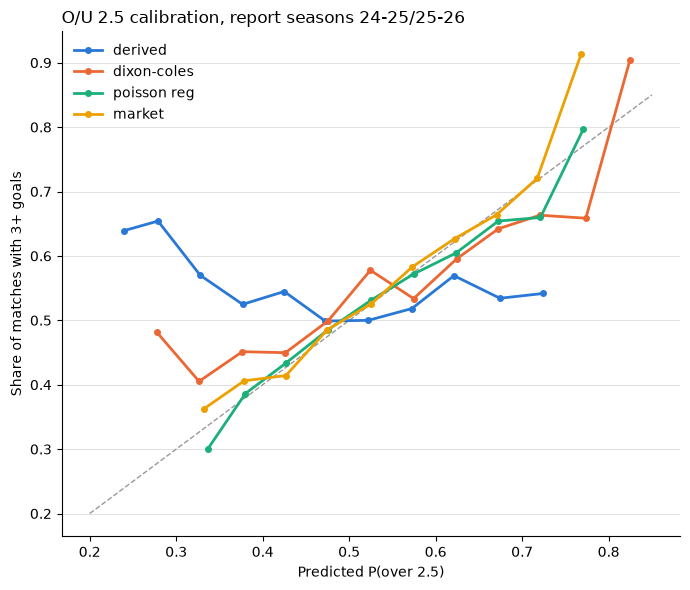

In [8]:
mask = PERIOD_MASK["report"]
bins = np.arange(0.2, 0.86, 0.05)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0.2, 0.85], [0.2, 0.85], color="#999999", linewidth=1, linestyle="--")
for (label, p), colour in zip([*[(m, P_OVER[m]) for m in MODELS], ("market", Q_OVER)], COLOURS):
    d = pd.DataFrame({"p": p[mask], "y": OVER[mask]}).dropna()
    d["bin"] = pd.cut(d["p"], bins)
    g = d.groupby("bin", observed=True).agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
    g = g[g["n"] >= 40]
    ax.plot(g["p"], g["y"], marker="o", markersize=4, linewidth=2, color=colour, label=label)
ax.set_xlabel("Predicted P(over 2.5)")
ax.set_ylabel("Share of matches with 3+ goals")
ax.set_title("O/U 2.5 calibration, report seasons 24-25/25-26", loc="left")
ax.legend(frameon=False, loc="upper left")
style(ax)
plt.tight_layout()
plt.show()

## Blend test

As P8-02: does the model add anything to the price? Logarithmic pool for a
two-way market, logit(p_blend) = a·logit(p_model) + b·logit(q), fitted on the
tuning seasons (AH: weighted half-stake loss), scored on the report seasons
against the market alone and against a market-only recalibration
(logit q scaled by b).

In [9]:
def fit_pool(p, q, loss, with_model=True):
    lp, lq = logit(np.clip(p, 1e-6, 1 - 1e-6)), logit(np.clip(q, 1e-6, 1 - 1e-6))
    def objective(x):
        a, b = (x if with_model else (0.0, x[0]))
        return loss(expit(a * lp + b * lq))
    res = minimize(objective, x0=[0.0, 1.0] if with_model else [1.0], method="Nelder-Mead",
                   options={"xatol": 1e-6, "fatol": 1e-9})
    return (res.x if with_model else (0.0, res.x[0]))

def pool(p, q, ab):
    return expit(ab[0] * logit(np.clip(p, 1e-6, 1 - 1e-6)) + ab[1] * logit(np.clip(q, 1e-6, 1 - 1e-6)))

BLEND, BLEND_P = {}, {}
rows = []
for market in MARKETS:
    p = P_OVER[CHOSEN_MODEL[market]] if market == "OU25" else P_AH[CHOSEN_MODEL[market]]
    q = Q_OVER if market == "OU25" else Q_AH
    tune = PERIOD_MASK["tune"] & np.isfinite(p) & np.isfinite(q)
    if market == "OU25":
        loss = lambda x: binary_ll(x, OVER[tune]).mean()
    else:
        def loss(x):
            l, w = ah_log_loss(x, MARGIN[tune], LINE[tune])
            return l.sum() / w.sum()
    ab = fit_pool(p[tune], q[tune], loss)
    recal = fit_pool(p[tune], q[tune], loss, with_model=False)
    BLEND[market] = ab
    BLEND_P[market] = pool(p, q, ab)
    compare = compare_ou if market == "OU25" else compare_ah
    for period in ["report", "26-27"]:
        vs_market = compare(BLEND_P[market], PERIOD_MASK[period], q)
        vs_recal = compare(BLEND_P[market], PERIOD_MASK[period], pool(p, q, recal))
        rows.append({"market": market, "model": CHOSEN_MODEL[market], "a (model)": ab[0], "b (market)": ab[1],
                     "model share": ab[0] / (ab[0] + ab[1]), "recal b": recal[1], "period": period,
                     "vs market": vs_market["diff"], "CI": f"[{vs_market['ci_low']:+.4f}, {vs_market['ci_high']:+.4f}]",
                     "vs recalibrated market": vs_recal["diff"],
                     "CI ": f"[{vs_recal['ci_low']:+.4f}, {vs_recal['ci_high']:+.4f}]"})
pd.DataFrame(rows).round(4)

,market,model,a (model),b (market),model share,recal b,period,vs market,CI,vs recalibrated market,CI
0,OU25,poisson reg,0.0486,1.1638,0.0401,1.2079,report,0.0005,"[-0.0007, +0.0016]",0.0000,"[-0.0001, +0.0002]"
1,OU25,poisson reg,0.0486,1.1638,0.0401,1.2079,26-27,-0.0012,"[-0.0049, +0.0025]",-0.0003,"[-0.0006, +0.0001]"
2,AH,poisson reg,0.0705,1.1749,0.0566,1.2390,report,0.0005,"[+0.0000, +0.0010]",0.0004,"[+0.0001, +0.0007]"
3,AH,poisson reg,0.0705,1.1749,0.0566,1.2390,26-27,-0.0009,"[-0.0021, +0.0003]",-0.0007,"[-0.0017, +0.0003]"


## Betting: arrays, rules and the evaluator

Per market and side: opening and closing price per source, the realised return
of 1 unit (simulator rules: push = stake back, quarter lines half and half), and
each model's (A, B). AH closing-line value only counts where the closing line
equals the opening line (as `simulate()`).

A rule picks at most one side per match:

- **side / favourite / underdog:** baselines (always over, always under, always
  home or away on the handicap, the shorter or longer price).
- **threshold:** the side with fair probability ≥ t.
- **value:** the side with the larger edge = A·o + B - 1 ≥ e at the price taken,
  optionally within an odds band. Probabilities: the chosen model (raw), the
  blend above, or one of the other two goals models.

`select()` is used both by the fast evaluator and inside simulator strategies,
and the next cell checks the evaluator against `simulate()`.

In [10]:
SIDE_COLUMN = {"O": "O", "U": "U", "H": "AHH", "A": "AHA"}  # simulate's o<...>/c<...> suffixes
ODDS, CLOSE, RETURN = {}, {}, {}
for market, sides in MARKETS.items():
    for source in SOURCES:
        o = np.full((N, 2), np.nan)
        c = np.full((N, 2), np.nan)
        r = np.full((N, 2), np.nan)
        for j, side in enumerate(sides):
            op, cl = prices(oos, source, market, side)
            o[:, j], c[:, j] = op.to_numpy(float), cl.to_numpy(float)
            if market == "OU25":
                won = OVER if side == "O" else ~OVER
                r[:, j] = np.where(won, o[:, j], 0.0)
            else:
                halves = ah_outcomes(MARGIN, LINE0, side)
                r[:, j] = np.where(halves > 0, o[:, j][:, None], np.where(halves == 0, 1.0, 0.0)).mean(axis=1)
                o[~LINE_OK, j] = np.nan
                c[(oos["AHCh"].to_numpy(float) != LINE), j] = np.nan
        ODDS[(market, source)], CLOSE[(market, source)], RETURN[(market, source)] = o, c, r

def coefficients(market, prob):
    """(A, B), each (N, 2), for a probability set: a model name or 'blend'."""
    if market == "OU25":
        p = BLEND_P["OU25"] if prob == "blend" else P_OVER[prob]
        return np.stack([p, 1 - p], axis=1), np.zeros((N, 2))
    if prob == "blend":
        # blended P(home covers | not pushed); pushes from the chosen model
        _, push_h = AH_COEF[CHOSEN_MODEL["AH"]]["H"]
        _, push_a = AH_COEF[CHOSEN_MODEL["AH"]]["A"]
        p = BLEND_P["AH"]
        return np.stack([p * (1 - push_h), (1 - p) * (1 - push_a)], axis=1), np.stack([push_h, push_a], axis=1)
    (a_h, b_h), (a_a, b_a) = AH_COEF[prob]["H"], AH_COEF[prob]["A"]
    return np.stack([a_h, a_a], axis=1), np.stack([b_h, b_a], axis=1)

COEF = {(m, prob): coefficients(m, prob) for m in MARKETS for prob in MODELS + ["blend"]}

def select(rule, A, B, odds):
    """Side index (0/1, -1 = no bet), edge and fair probability of the side, per row."""
    kind = rule["kind"]
    with np.errstate(invalid="ignore", divide="ignore"):
        fair = A / (1 - B)
        edge = A * odds + B - 1
    ok = np.isfinite(odds) & (odds > 1) & np.isfinite(fair)
    lo, hi = rule.get("band", (1.0, np.inf))
    ok &= (odds >= lo) & (odds <= hi)
    if kind == "side":
        score = np.where(np.arange(2) == rule["side"], 1.0, -np.inf) + 0 * odds
    elif kind in ("favourite", "underdog"):
        score = -odds if kind == "favourite" else odds
    elif kind == "threshold":
        ok &= fair >= rule["t"]
        score = fair
    elif kind == "value":
        ok &= edge >= rule["e"]
        score = edge
    score = np.where(ok, np.nan_to_num(score, nan=-np.inf, neginf=-1e9), -np.inf)
    side = score.argmax(axis=1)
    has = ok.any(axis=1)
    rows = np.arange(len(odds))
    return np.where(has, side, -1), edge[rows, side], fair[rows, side]

def run_rule(market, rule, source):
    A, B = COEF[(market, rule.get("prob", CHOSEN_MODEL[market]))]
    return select(rule, A, B, ODDS[(market, source)])

def evaluate(market, rule, source, period, sel=None):
    if sel is None:
        sel, _, _ = run_rule(market, rule, source)
    bet = (sel >= 0) & PERIOD_MASK[period]
    idx = np.flatnonzero(bet)
    s = sel[idx]
    ret = RETURN[(market, source)][idx, s]
    odds = ODDS[(market, source)][idx, s]
    closing = CLOSE[(market, source)][idx, s]
    profit = ret - 1
    weeks = PERIOD_WEEKS[period]
    n = len(idx)
    if n == 0:
        return {"bets": 0, "bets_per_week": 0.0, "hit_rate": np.nan, "avg_odds": np.nan, "roi": np.nan,
                "roi_ci_low": np.nan, "roi_ci_high": np.nan, "clv": np.nan, "profit": 0.0}
    by_week = (pd.DataFrame({"Week": oos["Week"].to_numpy()[idx], "profit": profit, "staked": 1.0})
               .groupby("Week").sum().reindex(weeks, fill_value=0.0))
    boot = bootstrap_roi(by_week)
    with np.errstate(invalid="ignore", divide="ignore"):
        clv = np.log(odds / closing)
    clv = clv[np.isfinite(clv)]
    return {"bets": n, "bets_per_week": n / len(weeks), "hit_rate": (ret > 1).mean() * 100,
            "avg_odds": odds.mean(), "roi": profit.sum() / n * 100,
            "roi_ci_low": boot["ci"][0] * 100, "roi_ci_high": boot["ci"][1] * 100,
            "clv": clv.mean() * 100 if len(clv) else np.nan, "profit": profit.sum()}

### Check: evaluator = simulator

Rules written as ordinary `simulate()` strategies (prices from the week's
`o<sel>` columns, stakes from a P8-04 staking plan) must give the evaluator's
numbers exactly: bets, profit, ROI and its CI, CLV.

In [11]:
def strategy(market, rule, plan=None):
    """A simulate() strategy for ``rule`` on ``market``; ``plan`` sizes stakes (flat 1u default)."""
    plan = plan or flat_plan(1.0)
    sides = MARKETS[market]
    A_all, B_all = COEF[(market, rule.get("prob", CHOSEN_MODEL[market]))]
    row_of = pd.Series(np.arange(N), index=oos["MatchKey"])

    def run(week, bankroll):
        rows = row_of[week["MatchKey"]].to_numpy()
        odds = week[[f"o{SIDE_COLUMN[s]}" for s in sides]].to_numpy(float)
        if market == "AH":
            odds = np.where(LINE_OK[rows][:, None], odds, np.nan)
        sel, edge, fair = select(rule, A_all[rows], B_all[rows], odds)
        chosen = np.flatnonzero(sel >= 0)
        if len(chosen) == 0:
            return []
        stakes = plan(fair[chosen], odds[chosen, sel[chosen]], edge[chosen], bankroll)
        keys = week["MatchKey"].to_numpy()
        return [single(keys[i], sides[sel[i]], float(st), market=market)
                for i, st in zip(chosen, stakes) if st > 0]
    return run

CHECKS = [
    ("OU25", {"kind": "threshold", "t": 0.55}),
    ("OU25", {"kind": "value", "e": 0.02, "prob": "blend"}),
    ("AH", {"kind": "value", "e": 0.04}),
    ("AH", {"kind": "favourite"}),
]
test_frame = oos[oos["Season"].isin(TEST)].drop(columns="Week")
rows = []
for market, rule in CHECKS:
    for source in SOURCES:
        sim = summarise(simulate(test_frame, strategy(market, rule), source=source)).loc["overall"]
        ev = evaluate(market, rule, source, "test")
        for metric in ["bets", "profit", "roi", "roi_ci_low", "roi_ci_high", "clv"]:
            assert abs(round(ev[metric], 2) - sim[metric]) < 0.011, (market, rule, source, metric, ev[metric], sim[metric])
        rows.append({"market": market, "rule": str(rule), "source": source, "bets": sim["bets"],
                     "roi": sim["roi"], "ci": f"[{sim['roi_ci_low']:+.2f}, {sim['roi_ci_high']:+.2f}]",
                     "clv": sim["clv"], "unpriced": sim["unpriced"]})
print("Evaluator matches simulate() on all checks")
pd.DataFrame(rows)

Evaluator matches simulate() on all checks


,market,rule,source,bets,roi,ci,clv,unpriced
0,OU25,"{'kind': 'threshold', 't': 0.55}",avg,5808.0,-3.47,"[-5.70, -1.33]",0.24,0.0
1,OU25,"{'kind': 'threshold', 't': 0.55}",b365,5808.0,-3.14,"[-5.35, -0.99]",0.35,0.0
2,OU25,"{'kind': 'threshold', 't': 0.55}",max,5803.0,-0.63,"[-2.93, +1.60]",-0.32,0.0
3,OU25,"{'kind': 'value', 'e': 0.02, 'prob': 'blend'}",avg,10.0,-26.10,"[-71.60, +34.00]",-2.68,0.0
4,OU25,"{'kind': 'value', 'e': 0.02, 'prob': 'blend'}",b365,55.0,-29.44,"[-47.52, -9.63]",2.04,0.0
5,OU25,"{'kind': 'value', 'e': 0.02, 'prob': 'blend'}",max,1808.0,1.89,"[-1.63, +5.47]",0.78,0.0
6,AH,"{'kind': 'value', 'e': 0.04}",avg,4801.0,-5.13,"[-7.46, -2.81]",0.04,0.0
7,AH,"{'kind': 'value', 'e': 0.04}",b365,5602.0,-3.37,"[-5.66, -1.07]",0.24,0.0
8,AH,"{'kind': 'value', 'e': 0.04}",max,6235.0,-1.77,"[-3.90, +0.35]",-0.67,0.0
9,AH,{'kind': 'favourite'},avg,9471.0,-3.43,"[-5.01, -1.81]",-2.18,0.0


## Variants

Per market (63 each, 126 in all):

| Family | Rule | Count |
|---|---|---|
| baseline | always side 1, always side 2, shorter price, longer price | 4 |
| threshold | chosen model's fair probability ≥ t, t = 0.500..0.700 step 0.025 | 9 |
| value raw | chosen model, edge ≥ e, e = 0..0.20 step 0.02 | 11 |
| value blend | blended probability, same e | 11 |
| value raw + band | raw, price in [1.70, 2.30] | 11 |
| value blend + band | blend, price in [1.70, 2.30] | 11 |
| value other model | each of the other two goals models, e = 0 / 0.05 / 0.10 | 6 |

O/U prices are mostly 1.5-2.8 and AH prices 1.7-2.2, so one band is enough.

In [12]:
EDGES = np.round(np.arange(0.0, 0.2001, 0.02), 2)
THRESHOLDS = np.round(np.arange(0.500, 0.7001, 0.025), 3)
BAND = (1.70, 2.30)
SIDE_NAMES = {"OU25": ["always over", "always under"], "AH": ["always home", "always away"]}

VARIANTS = {}
for market in MARKETS:
    others = [m for m in MODELS if m != CHOSEN_MODEL[market]]
    for j, name in enumerate(SIDE_NAMES[market]):
        VARIANTS[(market, "baseline", name)] = {"kind": "side", "side": j}
    VARIANTS[(market, "baseline", "shorter price")] = {"kind": "favourite"}
    VARIANTS[(market, "baseline", "longer price")] = {"kind": "underdog"}
    for t in THRESHOLDS:
        VARIANTS[(market, "threshold", f"p>={t:.3f}")] = {"kind": "threshold", "t": t}
    for e in EDGES:
        VARIANTS[(market, "value raw", f"raw e>={e:.2f}")] = {"kind": "value", "e": e}
        VARIANTS[(market, "value blend", f"blend e>={e:.2f}")] = {"kind": "value", "e": e, "prob": "blend"}
        VARIANTS[(market, "value raw + band", f"raw e>={e:.2f} odds {BAND[0]:.2f}-{BAND[1]:.2f}")] = {"kind": "value", "e": e, "band": BAND}
        VARIANTS[(market, "value blend + band", f"blend e>={e:.2f} odds {BAND[0]:.2f}-{BAND[1]:.2f}")] = {"kind": "value", "e": e, "band": BAND, "prob": "blend"}
    for other in others:
        for e in [0.0, 0.05, 0.10]:
            VARIANTS[(market, "value other model", f"{other} e>={e:.2f}")] = {"kind": "value", "e": e, "prob": other}

def run(variants, periods):
    rows = []
    for (market, family, variant), rule in variants.items():
        for source in SOURCES:
            sel, _, _ = run_rule(market, rule, source)
            for period in periods:
                rows.append({"market": market, "family": family, "variant": variant, "source": source,
                             "period": period, **evaluate(market, rule, source, period, sel)})
    return pd.DataFrame(rows)

print(len(VARIANTS), "variants:", pd.Series([k[0] for k in VARIANTS]).value_counts().to_dict())

126 variants: {'OU25': 63, 'AH': 63}


## Tuning seasons and the chosen rule per market

Only tuning-season numbers exist at this point.

In [13]:
tune = run(VARIANTS, ["tune"])
eligible = tune[(tune["source"] == "avg") & (tune["bets"] >= MIN_TUNE_BETS)]
CHOSEN = {}
cols = ["family", "variant", "bets", "bets_per_week", "hit_rate", "avg_odds", "roi", "roi_ci_low", "roi_ci_high", "clv"]
for market in MARKETS:
    ranked = eligible[eligible["market"] == market].sort_values(["roi", "bets"], ascending=[False, False])
    CHOSEN[market] = tuple(ranked.iloc[0][["market", "family", "variant"]])
    print(f"{market}: chosen on the tuning seasons -> {CHOSEN[market][1]} / {CHOSEN[market][2]}")
    display(ranked[cols].head(8).round(2))

OU25: chosen on the tuning seasons -> threshold / p>=0.675


,family,variant,bets,bets_per_week,hit_rate,avg_odds,roi,roi_ci_low,roi_ci_high,clv
33,threshold,p>=0.675,447,5.81,71.81,1.42,1.66,-4.63,7.49,0.92
27,threshold,p>=0.625,1021,13.26,67.68,1.50,0.96,-3.12,4.94,0.68
24,threshold,p>=0.600,1461,18.97,65.78,1.54,0.46,-3.26,4.10,0.49
6,baseline,shorter price,4802,62.36,60.08,1.67,-0.58,-2.80,1.57,0.25
30,threshold,p>=0.650,704,9.14,68.32,1.46,-0.74,-5.71,4.23,0.63
21,threshold,p>=0.575,2081,27.03,63.09,1.58,-1.21,-4.70,2.20,0.44
15,threshold,p>=0.525,3766,48.91,59.61,1.68,-1.56,-4.17,0.87,0.35
141,value raw + band,raw e>=0.16 odds 1.70-2.30,160,2.08,48.12,2.07,-1.64,-15.41,12.50,0.90


AH: chosen on the tuning seasons -> threshold / p>=0.675


,family,variant,bets,bets_per_week,hit_rate,avg_odds,roi,roi_ci_low,roi_ci_high,clv
222,threshold,p>=0.675,171,2.22,51.46,1.88,5.81,-7.12,17.52,-1.71
231,value blend,blend e>=0.00,184,2.39,52.72,1.85,2.88,-8.29,14.71,-1.49
237,value blend + band,blend e>=0.00 odds 1.70-2.30,184,2.39,52.72,1.85,2.88,-8.29,14.71,-1.49
219,threshold,p>=0.650,312,4.05,50.00,1.88,2.31,-7.53,11.67,-1.84
213,threshold,p>=0.600,981,12.74,47.60,1.89,-1.62,-6.45,3.21,-1.06
195,baseline,shorter price,4802,62.36,49.67,1.85,-1.82,-4.04,0.28,-2.06
228,value raw,raw e>=0.00,3775,49.03,47.10,1.93,-1.91,-4.48,0.69,-0.08
234,value raw + band,raw e>=0.00 odds 1.70-2.30,3775,49.03,47.10,1.93,-1.91,-4.48,0.69,-0.08


## Report seasons (24-25/25-26) and 26-27 to date

In [14]:
results = run(VARIANTS, list(PERIODS))
assert np.allclose(results[results["period"] == "tune"][["bets", "roi"]].to_numpy(dtype=float),
                   tune[["bets", "roi"]].to_numpy(dtype=float), equal_nan=True)

def show(market, family, variant):
    d = results[(results["market"] == market) & (results["family"] == family) & (results["variant"] == variant)]
    d = d.assign(ci=[f"[{lo:+.1f}, {hi:+.1f}]" for lo, hi in zip(d["roi_ci_low"], d["roi_ci_high"])])
    return d.set_index(["source", "period"])[["bets", "bets_per_week", "hit_rate", "avg_odds", "roi", "ci", "clv"]].round(2)

for market in MARKETS:
    print(f"== {market}: chosen rule {CHOSEN[market][1]} / {CHOSEN[market][2]}")
    display(show(*CHOSEN[market]))

== OU25: chosen rule threshold / p>=0.675


bets  bets_per_week  hit_rate  avg_odds   roi             ci   clv
source period                                                                    
avg    tune     447           5.81     71.81      1.42  1.66   [-4.6, +7.5]  0.92
       report   383           4.97     71.54      1.37 -3.06   [-8.8, +2.4]  0.25
       26-27     99           9.00     71.72      1.35 -4.19  [-12.9, +5.5]  1.03
b365   tune     447           5.81     71.81      1.42  1.60   [-4.7, +7.5]  0.97
       report   383           4.97     71.54      1.38 -2.33   [-8.1, +3.2]  0.39
       26-27     99           9.00     71.72      1.37 -2.49  [-11.5, +7.6]  1.50
max    tune     447           5.81     71.81      1.46  4.39  [-2.1, +10.4]  0.15
       report   382           4.96     71.47      1.40 -0.84   [-6.7, +4.8] -0.14
       26-27     99           9.00     71.72      1.38 -1.60  [-10.7, +8.4]  0.97

== AH: chosen rule threshold / p>=0.675


bets  bets_per_week  hit_rate  avg_odds    roi             ci   clv
source period                                                                     
avg    tune     171           2.22     51.46      1.88   5.81  [-7.1, +17.5] -1.71
       report   108           1.40     42.59      1.85 -13.18  [-28.1, +2.8] -1.33
       26-27     29           2.64     34.48      1.84 -27.26  [-64.9, +3.8] -0.20
b365   tune     171           2.22     51.46      1.91   6.87  [-6.1, +18.6] -1.69
       report   108           1.40     42.59      1.88 -11.45  [-26.8, +4.9] -1.24
       26-27     29           2.64     34.48      1.90 -25.74  [-64.4, +6.2]  0.28
max    tune     171           2.22     51.46      1.94   8.68  [-4.6, +20.7] -2.79
       report   107           1.39     42.06      1.91 -11.62  [-28.0, +5.7] -1.40
       26-27     29           2.64     34.48      1.90 -25.74  [-64.4, +6.2] -0.48

### Every family at a glance (avg odds)

Baselines and a few representative rules per family, tuning vs report.

In [15]:
avg = results[results["source"] == "avg"]
wide = avg.pivot_table(index=["market", "family", "variant"], columns="period", values=["bets", "roi", "clv"])
wide.columns = [f"{m} {p}" for m, p in wide.columns]
pick = [k for k in VARIANTS if k[1] in ("baseline", "value other model")
        or k[2] in ("p>=0.500", "p>=0.550", "p>=0.600", "raw e>=0.00", "raw e>=0.06", "raw e>=0.12",
                    "blend e>=0.00", "blend e>=0.04", f"raw e>=0.00 odds {BAND[0]:.2f}-{BAND[1]:.2f}",
                    f"blend e>=0.00 odds {BAND[0]:.2f}-{BAND[1]:.2f}")]
wide.loc[pick, ["bets tune", "roi tune", "clv tune", "bets report", "roi report", "clv report", "bets 26-27", "roi 26-27"]].round(2)

bets tune  roi tune  clv tune  bets report  roi report  clv report  bets 26-27  roi 26-27
market family             variant                                                                                                                
OU25   baseline           always over                      4802.0     -3.72     -0.83       4728.0       -5.07       -0.66       640.0      -2.06
                          always under                     4802.0     -7.37      0.09       4728.0       -6.99       -0.29       640.0     -13.39
                          shorter price                    4802.0     -0.58      0.25       4728.0       -4.91       -0.22       640.0      -3.93
                          longer price                     4802.0    -10.38     -1.01       4728.0       -7.15       -0.72       640.0     -12.40
       threshold          p>=0.500                         4802.0     -3.09      0.30       4728.0       -5.46       -0.03       640.0      -1.09
                          p>=0.550                         2847.0     -1.66      0.38       2961.0       -5.22        0.10       436.0      -2.75
                          p>=0.600                         1461.0      0.46      0.49       1501.0       -5.60        0.18       263.0       3.87
       value raw          raw e>=0.00                      3167.0     -6.78     -0.41       2519.0       -7.42       -0.08       298.0      -1.43
       value blend        blend e>=0.00                     398.0     -3.51      1.57        137.0       -3.74        0.79         0.0        NaN
       value raw + band   raw e>=0.00 odds 1.70-2.30       1858.0     -5.27     -0.14       1392.0       -9.63        0.26       124.0       0.33
       value blend + band blend e>=0.00 odds 1.70-2.30       13.0    -17.08      1.13          0.0         NaN         NaN         0.0        NaN
       value blend        blend e>=0.04                       3.0   -100.00     -0.71          1.0     -100.00      -22.08         0.0        NaN
       value raw          raw e>=0.06                      1673.0     -7.34     -0.46       1097.0       -5.66        0.04       134.0      -8.10
                          raw e>=0.12                       766.0     -8.75     -0.43        429.0       -4.47       -0.04        52.0      -7.35
       value other model  derived e>=0.00                  3996.0     -8.31     -0.93       3982.0       -6.23       -0.78       549.0     -15.25
                          derived e>=0.05                  3289.0     -9.30     -1.15       3430.0       -7.63       -0.81       482.0     -16.07
                          derived e>=0.10                  2722.0    -10.54     -1.22       2889.0       -7.99       -0.89       428.0     -18.37
                          dixon-coles e>=0.00              3519.0     -5.60     -0.27       3083.0       -5.80       -0.18       434.0      -8.47
                          dixon-coles e>=0.05              2380.0     -6.96     -0.32       1955.0       -7.41       -0.29       319.0     -13.38
                          dixon-coles e>=0.10              1472.0     -7.30     -0.38       1099.0       -9.54       -0.20       208.0     -13.87
AH     baseline           always home                      4802.0     -3.29     -0.04       4669.0       -7.23       -0.37       639.0      -8.93
                          always away                      4802.0     -3.54     -0.30       4669.0       -2.02       -0.28       639.0      -2.91
                          shorter price                    4802.0     -1.82     -2.06       4669.0       -5.08       -2.31       639.0      -2.60
                          longer price                     4802.0     -4.06      1.76       4669.0       -4.20        1.65       639.0      -9.24
       threshold          p>=0.500                         4802.0     -2.31     -0.58       4669.0       -7.79       -0.62       639.0       0.21
                          p>=0.550                         2566.0     -2.42     -0.80       2286.0       -6.75    

In [16]:
# Overfitting check: variants with >= 150 bets in both periods
both = wide[(wide["bets tune"] >= MIN_TUNE_BETS) & (wide["bets report"] >= MIN_TUNE_BETS)]
over = pd.DataFrame({
    market: {
        "variants": len(g),
        "ROI > 0 tune": int((g["roi tune"] > 0).sum()),
        "ROI > 0 report": int((g["roi report"] > 0).sum()),
        "ROI > 0 both": int(((g["roi tune"] > 0) & (g["roi report"] > 0)).sum()),
        "CLV > 0 report": int((g["clv report"] > 0).sum()),
        "tune-report ROI corr": round(g[["roi tune", "roi report"]].corr().iloc[0, 1], 2),
    } for market, g in both.groupby(level="market")
}).T
over

,variants,ROI > 0 tune,ROI > 0 report,ROI > 0 both,CLV > 0 report,tune-report ROI corr
AH,39.0,1.0,0.0,0.0,19.0,0.23
OU25,36.0,3.0,3.0,0.0,20.0,0.12


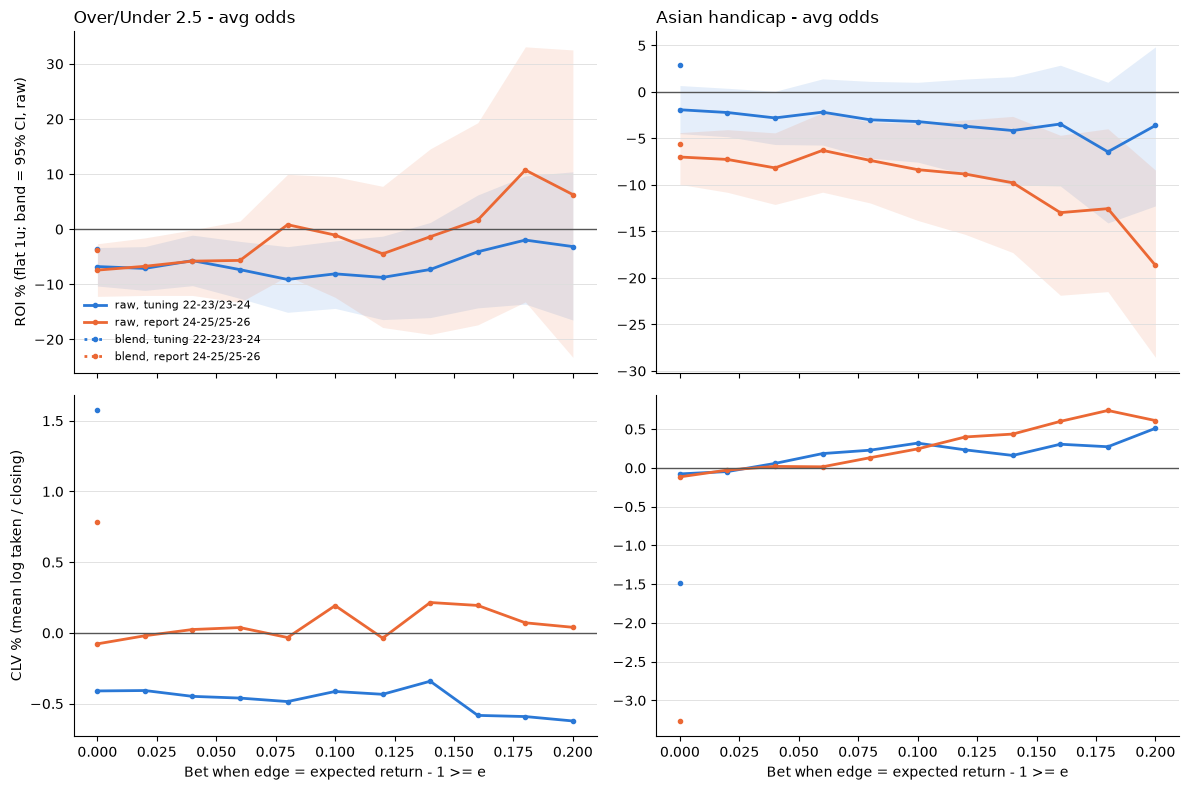

In [17]:
base = results[results["family"].isin(["value raw", "value blend"]) & (results["source"] == "avg")].copy()
base["prob"] = base["variant"].str.split().str[0]
base["e"] = base["variant"].str.extract(r"e>=([\d.]+)")[0].astype(float)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for col, market in enumerate(MARKETS):
    for prob, ls in [("raw", "-"), ("blend", ":")]:
        for period, colour, label in [("tune", TUNE_COLOUR, "tuning 22-23/23-24"), ("report", REPORT_COLOUR, "report 24-25/25-26")]:
            d = base[(base["market"] == market) & (base["prob"] == prob) & (base["period"] == period) & (base["bets"] >= 30)].sort_values("e")
            if prob == "raw":
                axes[0, col].fill_between(d["e"], d["roi_ci_low"], d["roi_ci_high"], color=colour, alpha=0.12, linewidth=0)
            axes[0, col].plot(d["e"], d["roi"], ls, color=colour, linewidth=2, marker="o", markersize=3, label=f"{prob}, {label}")
            axes[1, col].plot(d["e"], d["clv"], ls, color=colour, linewidth=2, marker="o", markersize=3, label=f"{prob}, {label}")
    axes[0, col].set_title(f"{'Over/Under 2.5' if market == 'OU25' else 'Asian handicap'} - avg odds", loc="left")
    axes[1, col].set_xlabel("Bet when edge = expected return - 1 >= e")
for ax in axes.flat:
    ax.axhline(0, color="#555555", linewidth=1)
    style(ax)
axes[0, 0].set_ylabel("ROI % (flat 1u; band = 95% CI, raw)")
axes[1, 0].set_ylabel("CLV % (mean log taken / closing)")
axes[0, 0].legend(frameon=False, loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

## Staking

The chosen rule per market on a 100-unit bankroll at avg odds (tuning and report
seasons each start at 100): flat 1u, 10u x edge, ¼ and ½ Kelly (5% a bet, 20% a
week cap). Kelly uses the fair probability A / (1 - B), exact for whole and
half lines, approximate for quarter lines. Risk of ruin = share of bootstrap
paths below 20u (P8-04's definition).

In [18]:
PLANS = {"flat 1u": flat_plan(1.0), "10u x edge": edge_plan(10.0), "1/4 Kelly": kelly_plan(0.25), "1/2 Kelly": kelly_plan(0.5)}
STAKES, RUNS = [], {}
for market in MARKETS:
    rule = VARIANTS[CHOSEN[market]]
    for period in PERIODS:
        frame = oos[oos["Season"].isin(PERIODS[period])].drop(columns="Week")
        for plan_name, plan in PLANS.items():
            res = simulate(frame, strategy(market, rule, plan), source="avg", bankroll=100.0, ruin_level=0.0)
            RUNS[(market, plan_name, period)] = res
            stats = bankroll_stats(res, multiplicative=plan_name != "flat 1u")
            STAKES.append({"market": market, "rule": CHOSEN[market][2], "plan": plan_name, "period": period,
                           "weeks": len(res.weeks), **stats, "clv": summarise(res).loc["overall", "clv"]})
stakes = pd.DataFrame(STAKES)
stakes.set_index(["market", "plan", "period"])[["bets", "staked", "roi", "final_bankroll", "max_drawdown_pct",
                                                "worst_week", "risk_of_ruin", "clv"]].round(2)

bets  staked    roi  final_bankroll  max_drawdown_pct  worst_week  risk_of_ruin   clv
market plan       period                                                                                       
OU25   flat 1u    tune     447  447.00   1.66          107.41             13.28       -3.09          0.00  0.92
       10u x edge tune     283  215.50   5.42          111.67              7.80       -4.60          0.00  1.01
       1/4 Kelly  tune     283  860.56   0.78          106.67             26.27      -12.91          0.00  1.01
       1/2 Kelly  tune     283  959.92   0.50          104.80             34.62      -11.95          0.02  1.01
       flat 1u    report   383  383.00  -3.06           88.28             17.75       -4.48          0.00  0.25
       10u x edge report   147   90.31 -14.66           86.76             14.73       -3.24          0.00  0.40
       1/4 Kelly  report   147  298.89 -13.27           60.35             43.39      -13.79          0.04  0.40
       1/2 Kelly  report   147  351.08 -13.38           53.04             50.62      -16.05          0.60  0.40
       flat 1u    26-27     99   99.00  -4.19           95.85              7.21       -3.80          0.00  1.03
       10u x edge 26-27     30   16.94   5.91          101.00              2.64       -2.31          0.00  2.27
       1/4 Kelly  26-27     30   77.96   5.90          104.60              9.50       -5.95          0.00  2.27
       1/2 Kelly  26-27     30  102.35   4.39          104.50              9.60       -6.91          0.00  2.27
AH     flat 1u    tune     171  171.00   5.81          109.93              6.72       -4.00          0.00 -1.71
       10u x edge tune     171  487.37   4.35          121.18             16.54      -12.47          0.00 -1.71
       1/4 Kelly  tune     171  771.64   2.39          118.46             30.97      -28.71          0.08 -1.71
       1/2 Kelly  tune     171  771.64   2.39          118.46             30.97      -28.71          0.08 -1.71
       flat 1u    report   108  108.00 -13.18           85.76             16.65       -3.34          0.00 -1.33
       10u x edge report   107  294.20 -19.66           42.16             59.09      -11.55          5.62 -1.33
       1/4 Kelly  report   107  323.16 -15.74           49.13             56.12      -15.65          2.62 -1.33
       1/2 Kelly  report   107  323.16 -15.74           49.13             56.12      -15.65          2.62 -1.33
       flat 1u    26-27     29   29.00 -27.26           92.10              7.90       -4.00          0.00 -0.20
       10u x edge 26-27     29   74.91 -26.91           79.84             20.16      -10.76          0.00 -0.20
       1/4 Kelly  26-27     29  105.49 -34.39           63.72             36.28      -17.50          0.02 -0.20
       1/2 Kelly  26-27     29  105.49 -34.39           63.72             36.28      -17.50          0.02 -0.20

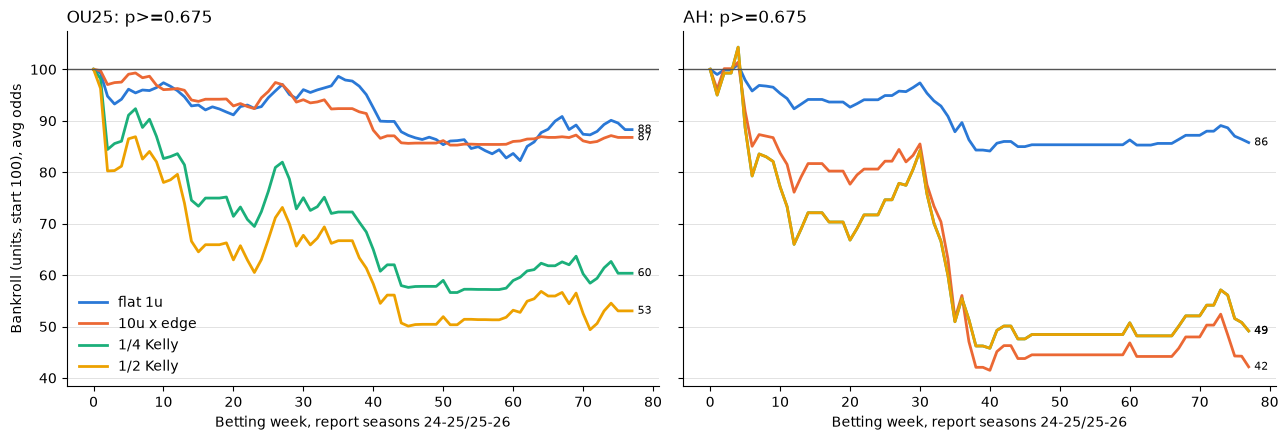

In [19]:
PLAN_COLOURS = dict(zip(PLANS, COLOURS))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, market in zip(axes, MARKETS):
    for plan_name in PLANS:
        path = np.concatenate([[100.0], bankroll_path(RUNS[(market, plan_name, "report")]).to_numpy()])
        ax.plot(np.arange(len(path)), path, color=PLAN_COLOURS[plan_name], linewidth=2, label=plan_name)
        ax.annotate(f"{path[-1]:.0f}", (len(path) - 1, path[-1]), xytext=(4, 0), textcoords="offset points", fontsize=8, va="center")
    ax.axhline(100, color="#555555", linewidth=1)
    ax.set_title(f"{market}: {CHOSEN[market][2]}", loc="left")
    ax.set_xlabel("Betting week, report seasons 24-25/25-26")
    style(ax)
axes[0].set_ylabel("Bankroll (units, start 100), avg odds")
axes[0].legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

## Variant log

In [20]:
sel_log = results.drop(columns="profit").assign(family=results["market"] + " " + results["family"],
                                                variant=results["market"] + " " + results["variant"])
stake_log = stakes.assign(
    family=stakes["market"] + " staking", variant=stakes["market"] + " " + stakes["rule"] + " | " + stakes["plan"], source="avg",
    bets_per_week=stakes["bets"] / stakes["weeks"], hit_rate=np.nan, avg_odds=np.nan,
    roi_ci_low=np.nan, roi_ci_high=np.nan,
)
log = log_variants(pd.concat([sel_log, stake_log], ignore_index=True), ticket="P8-06")
print(f"Logged {len(VARIANTS)} P8-06 selection variants + {stake_log.groupby(['family', 'variant']).ngroups} staking runs; "
      "log now holds", log.groupby("ticket")["variant"].nunique().to_dict())

Logged 126 P8-06 selection variants + 8 staking runs; log now holds {'P8-03': 274, 'P8-04': 331, 'P8-05': 67, 'P8-06': 134}


In [21]:
# For P8-07: weekly P&L of every P8-06 selection variant and the chosen rules' bets
from betting.variants import log_chosen_bets, log_variant_weeks, weekly_pnl

WEEK_LABEL, KEYS, SEASON, DIV = (oos[c].to_numpy() for c in ["Week", "MatchKey", "Season", "Div"])
weekly, bets = [], []
for (market, family, variant), rule in VARIANTS.items():
    for source in SOURCES:
        sel, _, _ = run_rule(market, rule, source)
        idx = np.flatnonzero(sel >= 0)
        s = sel[idx]
        profit = RETURN[(market, source)][idx, s] - 1
        weekly.append(weekly_pnl(WEEK_LABEL[idx], profit).assign(
            family=f"{market} {family}", variant=f"{market} {variant}", source=source))
        if (market, family, variant) == CHOSEN[market]:
            odds, closing = ODDS[(market, source)][idx, s], CLOSE[(market, source)][idx, s]
            with np.errstate(divide="ignore", invalid="ignore"):
                clv = np.log(odds / closing)
            bets.append(pd.DataFrame({
                "rule": f"{market} {variant}", "source": source, "Season": SEASON[idx], "Week": WEEK_LABEL[idx],
                "Div": DIV[idx], "MatchKey": KEYS[idx], "selection": np.array(MARKETS[market])[s], "odds": odds,
                "stake": 1.0, "profit": profit, "clv": np.where(np.isfinite(clv), clv, np.nan),
            }))
weekly = pd.concat(weekly, ignore_index=True)
want = (results.assign(family=results["market"] + " " + results["family"], variant=results["market"] + " " + results["variant"])
        .groupby(["family", "variant", "source"])["profit"].sum())
got = weekly.groupby(["family", "variant", "source"])["profit"].sum().reindex(want.index, fill_value=0.0)
assert np.allclose(got, want)
log_variant_weeks(weekly, ticket="P8-06")
log_chosen_bets(pd.concat(bets, ignore_index=True), ticket="P8-06")
print(f"Weekly P&L logged for {weekly.groupby(['family', 'variant']).ngroups} variants; chosen-rule bets:",
      pd.concat(bets).groupby(["rule", "source"]).size().to_dict())

Weekly P&L logged for 111 variants; chosen-rule bets: {('AH p>=0.675', 'avg'): 308, ('AH p>=0.675', 'b365'): 308, ('AH p>=0.675', 'max'): 307, ('OU25 p>=0.675', 'avg'): 929, ('OU25 p>=0.675', 'b365'): 929, ('OU25 p>=0.675', 'max'): 928}


## Findings

**Verdict: no edge in the goals markets either.** The best goals model is closer to the market than the 1X2
model is (O/U log loss +0.006 vs +0.021 for 1X2), but it is still worse in both markets. A blend gives it about 5%
weight and gains nothing. No betting rule holds up from the tuning seasons to the report seasons.

**Goals models** (22-23..25-26, model - market log loss, 95% CI):

| Model | O/U 2.5 | AH |
|---|---|---|
| (a) derived from H/D/A | +0.065 [+0.058, +0.072] | +0.026 [+0.021, +0.031] |
| (b) Dixon-Coles | +0.015 [+0.012, +0.019] | +0.025 [+0.020, +0.030] |
| **(c) Poisson regression (chosen for both)** | **+0.006 [+0.004, +0.009]** | **+0.013 [+0.010, +0.017]** |

- (c) is worse than the market in tuning, report and pooled for both markets. 26-27 to date (Avg only, ~640
  matches): O/U +0.0005 [-0.007, +0.008], AH +0.003 [-0.011, +0.017], level with the market but no better.
  Against the closing O/U price: +0.009.
- By league, O/U: E0, I1, N1 and P1 have CIs that cross 0, but no league is below 0. AH: worse everywhere
  except N1 (CI crosses 0). By AH line: whole +0.021, half +0.008, quarter +0.013, all > 0.
- (a) is badly biased on totals: mean P(over) 0.45 against an actual 0.54. It is also *inversely* calibrated:
  low-draw matches get high λs, and those don't have more goals. On margins (AH) it is about as good as
  Dixon-Coles.

**Blend (tuned 22-23/23-24, scored 24-25/25-26):** O/U model share 4%: vs market +0.0005 [-0.0007, +0.0016],
vs recalibrated market 0.0000. AH model share 6%: +0.0005 [0.0000, +0.0010]. The model adds nothing to the
price. The market alone gains from being stretched (logit x1.21 O/U, x1.24 AH), the same favourite-longshot
under-confidence P8-02 found in 1X2. As a result, blended "value" bets exist almost only at Pinnacle-vs-Avg
gaps: 10 O/U bets at avg over four seasons.

**Chosen rules** (both "fair probability >= 0.675", chosen on tuning seasons at avg):

| | Bets | avg ROI % | max ROI % | CLV avg |
|---|---|---|---|---|
| O/U tune | 447 | +1.7 [-4.6, +7.5] | +4.4 | +0.92 |
| **O/U report** | 383 | **-3.1 [-8.8, +2.4]** | -0.8 | +0.25 |
| O/U 26-27 | 99 | -4.2 | -1.6 | +1.03 |
| AH tune | 171 | +5.8 [-7.1, +17.5] | +8.7 | -1.71 |
| **AH report** | 108 | **-13.2 [-28.1, +2.8]** | -11.6 | -1.33 |
| AH 26-27 | 29 | -27.3 | -25.7 | -0.20 |

Report-season baselines (avg): O/U always over -5.1, under -7.0, shorter price -4.9. AH home -7.2,
away -2.0, shorter price -5.1.

- **Value bets** at raw model edges lose at every threshold: O/U -6..-9% tune, -4..-10% report; AH -2..-6%
  tune, -6..-19% report (worse at higher edges). Odds band 1.70-2.30 changes nothing. The other two goals
  models do worse.
- **Overfitting:** with >= 150 bets in both periods, O/U had 36 variants (3 positive in tuning, 3 in report,
  0 in both) and AH 39 (1 / 0 / 0). Tune-report ROI correlation +0.12 / +0.23.
- **CLV is not a clean signal here.** O/U confident picks show small positive CLV (+0.25..+1.0), but so does the
  shorter-price baseline in tuning (+0.25). AH CLV mostly follows the side: always-longer +1.7, always-shorter
  -2.1, and both lose. That's how Avg prices move when the line holds (AH CLV only counts unchanged lines), not
  skill. Raw AH value CLV rises with the edge while ROI falls.
- **Staking** (100u, avg, report seasons): every plan ends below 100. O/U flat 88, 10u x edge 87, 1/4 Kelly 60,
  1/2 Kelly 53. AH flat 86, 10u x edge 42, Kelly 49 (1/4 and 1/2 are identical because the 5%-a-bet cap binds
  on every bet).

**For P6-02:** the derived-λ method is fine for what P6-02 uses it for, the margin of a single tie (AH log loss
level with Dixon-Coles). It shouldn't be used for anything that depends on total goals. A goals model on xG
form (c) is better at margins too (+0.013 vs +0.026 against the AH market), but it needs features the CL path
doesn't build. Leave P6-02 as it is.

**Variant log:** 126 P8-06 selection variants (63 per market) + 8 staking runs, ticket `P8-06` in
`betting_variants.csv` (806 in total). For P8-07, P8-06's entries are the two chosen rules above.